# The maximal learning student

The student calibrated to people (`rush_hour_session.ipynb`) hardly learns on its own over a session, so there is little learning for a teacher to help or hinder. Before sweeping agency (how much a shown move teaches), this notebook looks for the pure-intuition student that learns the most on its own. It is not compared with people: the session's puzzles, the tests and the human limits on learning are all free to change.

**Fixed:**
- the starting network (`INIT`, the one fitted to people's first trials);
- one attempt per puzzle, and learning online: after every 30 puzzles it learns from those 30 alone, with no replay of earlier ones.

**Puzzles.** People's puzzle lengths (6-15 moves) are too easy for this network once it may not give up: it solves 93% of them. The session and the tests here use four length bins, 9-11, 14-16, 19-21 and 24-26 moves, from which the starting network solves 96%, 77%, 59% and 38% (68% overall, with up to 10x the optimal length in moves).

**Tests.** Every 540 puzzles, each student's network plays 50 held-out puzzles per bin, 3 attempts each, untaught, without giving up (up to 10x the optimal length in moves). The score is **moves / optimal, with an unsolved attempt counted at its move cap** (10x): lower is better, and it rewards both solving more and solving in fewer moves.

**Relaxed one at a time**, in stages. Each stage starts from the best student so far:
1. **Learning rate** (start: 1e-4).
2. **Passes over each update's examples** (`--steps`; start: 3).
3. **Giving up during the session** (start: as people do, x 0.4, so a puzzle given up on teaches nothing).
4. **Session length**: 4x the puzzles (72 per bin x 30 instead of 18 x 30).

The candidates are picked on the same held-out puzzles they are reported on, a mild optimistic bias; each stage picks between a handful of settings, each averaged over 8 students and 600 test attempts.

In [1]:
import sys
sys.path.append("../scripts")
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import session_experiment as se
import teach_experiment as te

## Settings and runs

`START` is where the stages start. Each stage lists its candidates as changes to the best student so far; `run_name` names a no-teacher run under `models/sessions/` after the settings that differ from `START` (`learn_start` for `START` itself).

A run of 8 students x 2,160 puzzles takes roughly 45-60 minutes on 8 cores, about 12 of them testing (the students run in parallel, one per core, so fewer students don't save time); without giving up the session's puzzles run longer, and stage 4 has 4x the puzzles. Each stage's cell prints the commands for its missing runs (run them from `scripts/`, one at a time - each uses every core), or set `RUN_HERE = True` to run them in the notebook (it is busy until they finish). A stage waits until the stage before it has finished, since it starts from that stage's best.

In [2]:
INIT = "../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt"
BINS = ["9-11", "14-16", "19-21", "24-26"]  # session and test puzzles, by optimal length
START = {"students": 8, "session_bins": BINS, "multiplier": 30, "per_bin": 18, "lr": 1e-4, "window": -1, "steps": 3,
         "max_attempts": 1, "surrender": True, "surrender_scale": 0.4, "test_per_bin": 50, "init": INIT}
OUT = se.OUT
RUN_HERE = False  # True: run each stage's missing runs here (hours; the notebook is busy until done)
NAMED = {"lr": "lr", "steps": "steps", "surrender": "giveup", "per_bin": "bin"}  # settings the stages change, in run names


def run_name(settings):
    """learn_ + the settings that differ from START, e.g. learn_lr0.001_steps10 (learn_start: none)."""
    other = [k for k in settings if k not in NAMED and settings[k] != START.get(k)]
    assert not other, f"no run name for changed settings {other}"
    differs = [k for k in NAMED if settings[k] != START[k]]
    return "learn_" + ("_".join(f"{NAMED[k]}{'on' if settings[k] else 'off'}" if isinstance(settings[k], bool) else
                                f"{NAMED[k]}{settings[k]:g}" for k in differs) or "start")


def argv(settings):
    """session_experiment's command line (after the run name) for a no-teacher run with these settings."""
    out = ["--teachers", "none"]
    for k, v in settings.items():
        flag = "--" + k.replace("_", "-")
        if isinstance(v, bool):
            out += [flag] if v else []
        elif isinstance(v, list):
            out += [flag, *map(str, v)]
        else:
            out += [flag, str(v)]
    return out


def load(settings):
    """The run's no-teacher entry ({"name", "config", "sessions", "results"}), or None until it is saved."""
    name = run_name(settings)
    if not os.path.exists(os.path.join(OUT, name, "config.json")):
        return None
    run = se.load_session(name, OUT)
    entry = run["teachers"].get("no teacher")
    if not entry or not entry["sessions"] or not entry["results"]:
        return None
    return {"name": name, "config": run["config"], **entry}


def measures(attempts, config):
    """(score, solve rate, moves / optimal over solved attempts) of test attempts; score: moves / optimal with an
    unsolved attempt counted at its move cap."""
    score = [(a["moves"] if a["solved"] else te.step_cap(a["distance"], config)) / a["distance"] for a in attempts]
    solved = [a["moves"] / a["distance"] for a in attempts if a["solved"]]
    return np.mean(score), np.mean([a["solved"] for a in attempts]), np.mean(solved) if solved else np.nan


def curve(run):
    """[(puzzles played, {measure: (mean, standard error across students)})] along the session."""
    points = sorted({n for by_n in run["results"].values() for n in by_n})
    out = []
    for n in points:
        per = [measures(by_n[n], run["config"]) for by_n in run["results"].values() if n in by_n]
        out.append((n, {key: te.mean_se([p[k] for p in per]) for k, key in
                        enumerate(("score", "solve rate", "moves / optimal (solved)"))}))
    return out


def final(run):
    """{student: (score, solve rate, moves / optimal over solved)} at the end of the session."""
    return {s: measures(by_n[max(by_n)], run["config"]) for s, by_n in run["results"].items()}

In [3]:
def stage(title, candidates, incumbent):
    """Runs (or prints the commands for) the stage's missing runs, plots their tests and returns the best
    candidate's settings (lowest final score) - or None while any is missing."""
    missing = [c for c in candidates if load(c) is None]
    if missing and RUN_HERE:
        os.chdir("../scripts")  # relative paths (--init) are resolved from where the run starts
        try:
            for c in missing:
                se.main([run_name(c), *argv(c)])
        finally:
            os.chdir("../notebooks")
        missing = [c for c in candidates if load(c) is None]
    if missing:
        print(f"{title}: waiting for {', '.join(run_name(c) for c in missing)}. From scripts/:")
        for c in missing:
            print("  python session_experiment.py", run_name(c), " ".join(argv(c)))
    runs = {run_name(c): load(c) for c in candidates}
    runs = {name: r for name, r in runs.items() if r is not None}
    if not runs:
        return None

    base = run_name(incumbent)
    keys = ("score", "solve rate", "moves / optimal (solved)")
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    rows = []
    for k, (name, run) in enumerate(runs.items()):
        points = curve(run)
        for ax, key in zip(axes, keys):
            ax.errorbar([n for n, _ in points], [r[key][0] for _, r in points],
                        yerr=[r[key][1] if r[key][1] == r[key][1] else 0 for _, r in points],
                        marker="o", capsize=3, color=f"C{k}", label=name + (" (best so far)" if name == base else ""))
        end = final(run)
        row = {"run": name, "puzzles": points[-1][0],
               "solved as played": np.mean([e["solved"] for record in run["sessions"].values() for e in record])}
        row |= {f"test {key}": te.mean_se([v[i] for v in end.values()]) for i, key in enumerate(keys)}
        if name != base and base in runs:
            base_end = final(runs[base])
            d = [end[s][0] - base_end[s][0] for s in end]
            row["score vs best so far (paired)"] = f"{np.mean(d):+.3f} ± {te.mean_se(d)[1]:.3f} ({sum(x < 0 for x in d)}/{len(d)} better)"
        rows.append(row)
    axes[0].set_ylabel("Moves / optimal, unsolved at the cap (test)")
    axes[1].set_ylabel("Solve rate (test)")
    axes[2].set_ylabel("Moves / optimal, solved (test)")
    for ax in axes:
        ax.set_xlabel("Simulated puzzles played")
    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    table = pd.DataFrame(rows)
    for key in keys:
        table[f"test {key}"] = [f"{m:.3f} ± {s:.3f}" for m, s in table[f"test {key}"]]
    display(table.round(3).fillna(""))
    if missing:
        return None
    best = min(candidates, key=lambda c: np.mean([v[0] for v in final(runs[run_name(c)]).values()]))
    print(f"best: {run_name(best)}")
    return best

## Stage 1: learning rate

The start learns at 1e-4 (the ExIt pretraining used 1e-3). Too high a rate can make online learning unstable - each update sees only 30 puzzles - which the test curve shows as a rise in the score late in the session, not only at the end. If the best rate is at either edge of the grid, extend the grid (the first grid stopped at 1e-4, its best, so 3e-5 and 1e-5 were added).

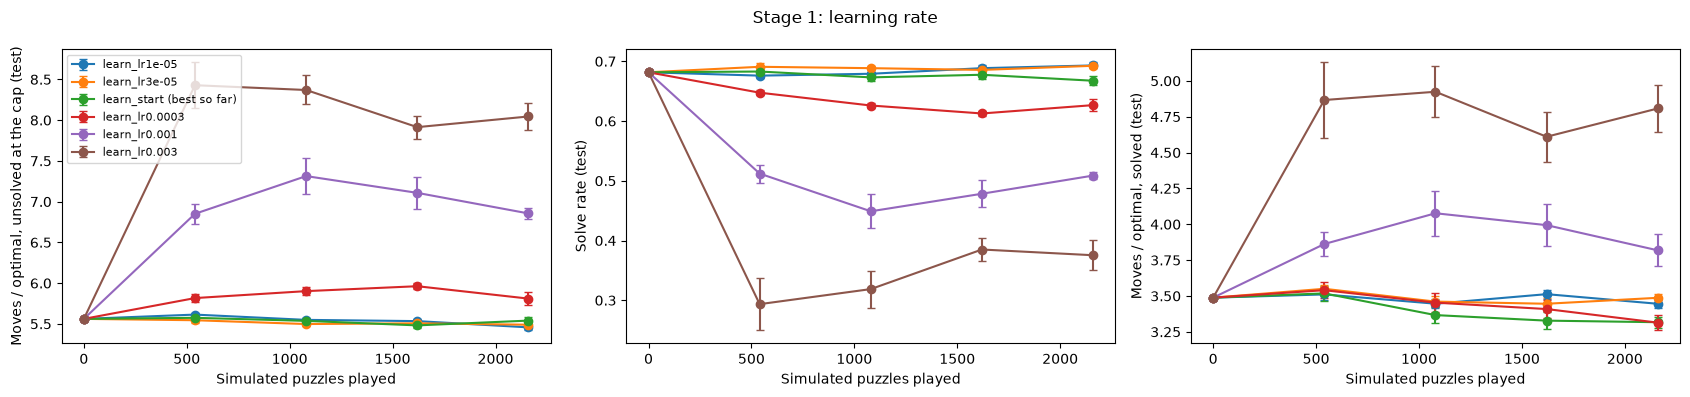

,run,puzzles,solved as played,test score,test solve rate,test moves / optimal (solved),score vs best so far (paired)
0,learn_lr1e-05,2160,0.635,5.457 ± 0.034,0.693 ± 0.005,3.446 ± 0.028,-0.083 ± 0.048 (5/8 better)
1,learn_lr3e-05,2160,0.636,5.490 ± 0.037,0.693 ± 0.004,3.487 ± 0.027,-0.051 ± 0.061 (5/8 better)
2,learn_start,2160,0.634,5.540 ± 0.043,0.667 ± 0.007,3.317 ± 0.038,
3,learn_lr0.0003,2160,0.601,5.810 ± 0.077,0.627 ± 0.010,3.314 ± 0.052,+0.270 ± 0.095 (1/8 better)
4,learn_lr0.001,2160,0.473,6.855 ± 0.063,0.509 ± 0.005,3.818 ± 0.111,+1.315 ± 0.068 (0/8 better)
5,learn_lr0.003,2160,0.339,8.045 ± 0.161,0.375 ± 0.025,4.807 ± 0.165,+2.505 ± 0.180 (0/8 better)


best: learn_lr1e-05
the best learning rate is at the edge of the grid: extend LEARNING_RATES


In [4]:
LEARNING_RATES = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3]
best = stage("Stage 1: learning rate", [START | {"lr": lr} for lr in LEARNING_RATES], START)
if best is not None and best["lr"] in (min(LEARNING_RATES), max(LEARNING_RATES)):
    print("the best learning rate is at the edge of the grid: extend LEARNING_RATES")

## Stage 2: passes over each update's examples

More passes over the same 30 puzzles' examples (`--steps`) is more learning from each without replaying older ones - it overlaps with the learning rate, so it is tried at stage 1's best rate.

Stage 2: passes per update: waiting for learn_lr1e-05_steps1, learn_lr1e-05_steps10. From scripts/:
  python session_experiment.py learn_lr1e-05_steps1 --teachers none --students 8 --session-bins 9-11 14-16 19-21 24-26 --multiplier 30 --per-bin 18 --lr 1e-05 --window -1 --steps 1 --max-attempts 1 --surrender --surrender-scale 0.4 --test-per-bin 50 --init ../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt
  python session_experiment.py learn_lr1e-05_steps10 --teachers none --students 8 --session-bins 9-11 14-16 19-21 24-26 --multiplier 30 --per-bin 18 --lr 1e-05 --window -1 --steps 10 --max-attempts 1 --surrender --surrender-scale 0.4 --test-per-bin 50 --init ../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt


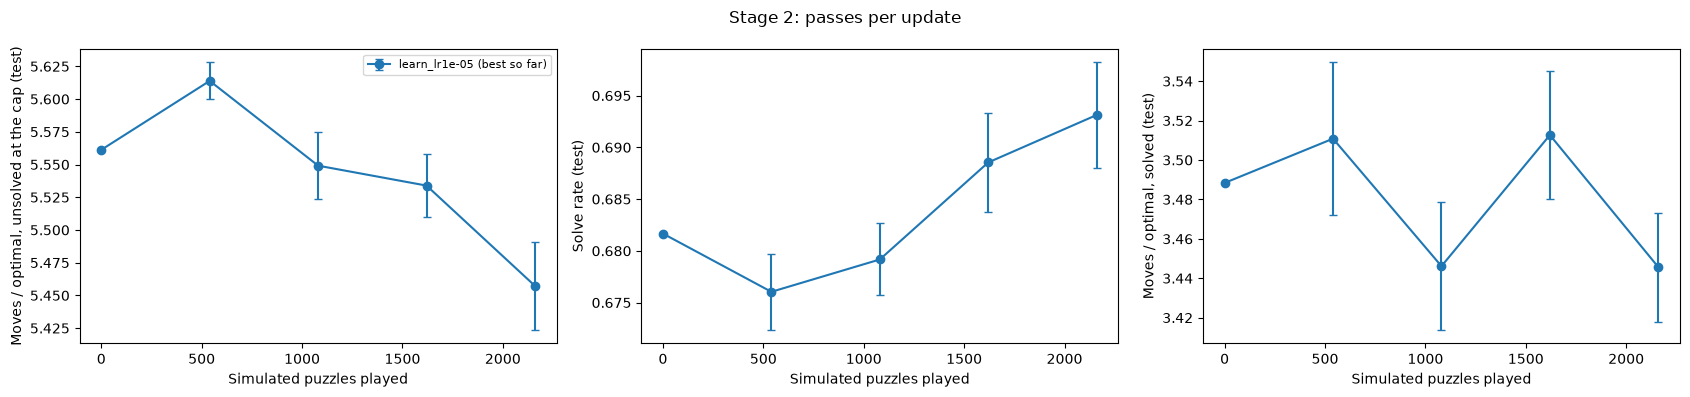

,run,puzzles,solved as played,test score,test solve rate,test moves / optimal (solved)
0,learn_lr1e-05,2160,0.635,5.457 ± 0.034,0.693 ± 0.005,3.446 ± 0.028


In [5]:
STEPS = [1, 3, 10]
if best is not None:
    best = stage("Stage 2: passes per update", [best | {"steps": s} for s in STEPS], best)

## Stage 3: giving up during the session

People give up on a puzzle, and the start does too (people's rates x 0.4); a puzzle given up on is unsolved and teaches nothing. Without giving up, the student keeps going until the move cap, so it solves more puzzles - along longer paths, whose loops are cut out before it learns from them.

In [6]:
if best is not None:
    best = stage("Stage 3: giving up during the session", [best, best | {"surrender": False}], best)

## Stage 4: session length

4x the puzzles (72 per bin x 30), in blocks of 30 as before, tested every 540 puzzles. The first 2,160 puzzles are a different sample from the shorter session's, so the curves are what to compare: the table's paired difference only matches students by number. The longer session shows where the student's learning levels off, if it does.

In [7]:
LONGER = 72  # puzzles per bin (x the multiplier); the start has 18
if best is not None:
    best = stage("Stage 4: session length", [best, best | {"per_bin": LONGER}], best)

## The maximal learning student

The settings the agency sweep starts from, and how much more it learns than the start's settings.

In [8]:
if best is None:
    print("not all stages have finished")
else:
    print("settings:", {k: v for k, v in best.items() if v != START.get(k)})
    print("run:", run_name(best))
    print("command line:", " ".join(argv(best)).replace("--teachers none ", ""))
    rows = []
    for label, settings in (("start", START), ("maximal", best)):
        for n, r in curve(load(settings)):
            rows.append({"student": label, "puzzles": n} | {key: round(m, 3) for key, (m, _) in r.items()})
    print(pd.DataFrame(rows).to_string(index=False))

not all stages have finished


# Teacher sweep on the shortcut student

## The shortcut student

The stages above barely move the student (score 5.56 at the start, about 5.2 at best), and the higher learning rates crash early on. The crash comes from what the student learns from, not from the optimizer. Its own solved paths, with loops cut out, are poor labels: only 54% of their target moves are optimal, and their moves-left targets are about 2x the true distance. Learning from them faster makes it worse.

**Shortcut labels** (`rl.shortcut_routes`) are hindsight over everything the student saw in a solved attempt. Two visited boards are joined when one legal move turns one into the other. The label is the shortest route to the solved board through those boards (1.5x optimal from the start, instead of 2.4x):
- `--labels path` labels the boards on the shortest routes from the start (69% of target moves optimal);
- `--labels all` labels every visited board that reaches the solved board (55% optimal, about twice as many labels). Offline, on the first 540 puzzles of one student, they took the score from 5.6 to about 5.0, as far as exact (BFS) labels on the same boards did. That is the learning the 4x-longer session of own labels didn't reach.

**How far learning from its own play can go.** An offline test took one student's 540 or 2,160 session puzzles, played once by the starting network. It trained on all of the resulting labels together for up to 30 passes, then tested on 200 held-out attempts (start: 5.30). Best scores reached:

| labels | 540 puzzles | 2,160 puzzles |
|---|---|---|
| own (loops cut out) | 4.75 (10 passes) | 4.65 (10) |
| shortcut, path | 4.35 (10) | 4.23 (3) |
| shortcut, every visited board | 4.20 (10) | 4.18 (10) |
| exact (BFS) labels on the boards of own | 3.50 (30) | |

- Shortcut labels beat the student's own at every point.
- Labelling every visited board ("all") learns fastest. After 1 pass it scores 4.75 against 5.17 for path labels (540 puzzles), and 4.33 against 4.74 (2,160). That matters most online, where each example is learned from only a few times.
- All of the student's own labels level off near 4.2 and get worse after 10 passes, as the network fits their mistakes.
- Exact labels on the same boards keep improving, to 3.5.
- 4x the puzzles speeds learning but hardly moves the ceiling, so label quality, not data, is what limits it.
- The gap between 4.2 and 3.5 is what a teacher's optimal moves could add.

The shortcut student is `START` with shortcut labels on every visited board: learning rate 1e-4 and 3 passes per update, over the 2,160-puzzle session. Stage 2's 10 passes per update hurt, since 10 passes over one block of 30 puzzles fits that block alone.

## The sweep

Each turn, the teacher (`random:p`) shows the optimal move with probability `p`. The student plays it, and the move counts as part of the attempt. **Agency** (`--shown-weight`, `rl.agency_weights`) is how much a shown move teaches compared with one the student found itself: 1 the same, 0 nothing.

**The assistance dilemma.** Help makes the session go better: more puzzles solved, on shorter paths. Whether it helps learning depends on agency:
- At agency 1, a shown move is a free optimal label.
- At agency 0, it teaches nothing, and it takes the place of a move the student would have learned from.

In between, too little help leaves the student floundering, and too much leaves it little of its own to learn from. Held-out learning could then peak at some amount of help. The sweep looks for that peak:
- help `p` in 0 (no teacher), 0.03, 0.1, 0.3 and 1 (every move shown);
- agency 1, 0.3 and 0.

No teacher is the same run whatever the agency, so it runs once, in the agency-1 run. The other runs are compared with it, student by student: student *k* plays the same puzzles in the same order in every run.

The results are reported student by student:
- **as played**: the session itself, with the teacher's help: puzzles solved, and the share of moves shown;
- **learning**: the held-out score at the start minus at the end of the session (higher is more learning);
- **vs no teacher**: the end score minus no teacher's, paired by student (below 0 means the teacher helped learning).

The dilemma shows up if, at some agency, learning peaks at an amount of help between none and every move.

**Running.** Runs play in a background process (`run_queue.py`) that keeps going if the notebook is closed. Launching does nothing if that queue is already running or finished. The watch cells show a progress bar with the time left; stopping a watch cell only stops the watching. A results cell shows whatever is saved so far. Only one queue should run at a time: each uses every core.

In [9]:
import run_queue as rq

SHORTCUT = START | {"labels": "all"}
HELP = ["none", "random:0.03", "random:0.1", "random:0.3", "random:1.0"]


def launch(queue, runs):
    """Starts queue `queue` of (run name, settings, teachers) in the background (see run_queue.launch)."""
    os.chdir("../scripts")  # the runs resolve relative paths (--init) from scripts/
    try:
        rq.launch(queue, [(run, argv(settings)[2:] + ["--teachers", *teachers]) for run, settings, teachers in runs])
    finally:
        os.chdir("../notebooks")


def watch(queue):
    if os.path.exists(os.path.join(OUT, "queues", f"{queue}.json")):
        rq.watch(queue)  # refreshes every 30 s until the queue stops
    else:
        print(f"{queue} hasn't been launched")


def entry(run, spec):
    """A teacher's entry in a run ({"config", "sessions", "results"}), or None until it is saved."""
    if not os.path.exists(os.path.join(OUT, run, "config.json")):
        return None
    loaded = se.load_session(run, OUT)
    found = loaded["teachers"].get(se.teacher_name(spec))
    if not found or not found["sessions"] or not found["results"]:
        return None
    return {"config": loaded["config"], **found}


def dilemma(runs, none_run, title, figure=None):
    """Learning against help, one line per agency. `runs`: {agency: run name}; no teacher from `none_run`
    (the same at every agency). Saves the figure to `figure` if given."""
    rows = []
    none = entry(none_run, "none")
    for agency, run in [(None, none_run)] + list(runs.items()):
        for spec in (["none"] if agency is None else [t for t in HELP if t != "none"]):
            e = entry(run, spec)
            if e is None:
                continue
            records = [x for record in e["sessions"].values() for x in record]
            end = final(e)
            start = measures(e["results"][0][0], e["config"])[0]
            row = {"agency": np.nan if agency is None else agency,
                   "help": 0.0 if spec == "none" else float(spec.split(":")[1]), "teacher": se.teacher_name(spec),
                   "solved as played": np.mean([x["solved"] for x in records]),
                   "moves shown": sum(x["taught"] for x in records) / sum(x["moves"] for x in records),
                   "learning": te.mean_se([start - end[s][0] for s in end]),
                   "test solve rate": te.mean_se([end[s][1] for s in end])}
            if none is not None and spec != "none":
                base = final(none)
                d = [end[s][0] - base[s][0] for s in end if s in base]
                row["score vs no teacher"] = te.mean_se(d)
                row["better than none"] = f"{sum(x < 0 for x in d)}/{len(d)}"
            rows.append(row)
    if not rows:
        print("nothing saved yet")
        return
    table = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for k, agency in enumerate(runs):
        part = table[(table.agency == agency) | (table.teacher == "no teacher")].sort_values("help")
        x = part["help"].clip(lower=0.01)  # no teacher plotted at 0.01 on the log axis
        axes[0].plot(x, part["solved as played"], marker="o", color=f"C{k}", label=f"agency {agency:g}")
        axes[1].errorbar(x, [m for m, _ in part["learning"]], yerr=[s for _, s in part["learning"]],
                         marker="o", capsize=3, color=f"C{k}", label=f"agency {agency:g}")
    for ax in axes:
        ax.set_xscale("log")
        ax.set_xlabel("Help: chance the teacher shows each move (no teacher at 0.01)")
        ax.legend(fontsize=8)
    axes[0].set_ylabel("Session puzzles solved, as played")
    axes[1].set_ylabel("Learning: held-out score, start - end")
    axes[1].axhline(0, color="gray", lw=0.8)
    fig.suptitle(title)
    plt.tight_layout()
    if figure:
        plt.savefig(figure, dpi=150)
    plt.show()
    for key, sign in (("learning", "+"), ("test solve rate", ""), ("score vs no teacher", "+")):
        if key in table:
            table[key] = [f"{v[0]:{sign}.3f} ± {v[1]:.3f}" if isinstance(v, tuple) else "" for v in table[key]]
    display(table.round(3).fillna(""))

## Pilot: one agency, a shorter session

Before the full sweep, a pilot checks whether the dilemma shows up at all. It uses one agency, 0.1, low enough that help clearly has a cost, so learning should fall off at full help. The session is a third as long: 6 puzzles per bin x 30, or 720 puzzles. Offline, the "all" labels improved the score most within the first pass over 540 puzzles, so 720 should be enough to see learning. Tests stay at 50 puzzles per bin x 3 attempts, after 0, 360 and 720 puzzles.

That's 5 teacher runs, about 10-15 minutes each, so roughly an hour. If learning peaks between no help and full help, the full sweep below is worth running.

In [10]:
PILOT = SHORTCUT | {"shown_weight": 0.1, "per_bin": 6, "test_every": 12}
PILOT_RUN = "pilot_all_agency0.1"
launch("teacher_pilot", [(PILOT_RUN, PILOT, HELP)])

teacher_pilot: all 5 teacher runs are saved, nothing to play


In [11]:
watch("teacher_pilot")

c:\dev\GitHub\rush-hour\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
teacher_pilot: 100%|██████████| , finished: 5.0/5 teacher runs in 1h40m


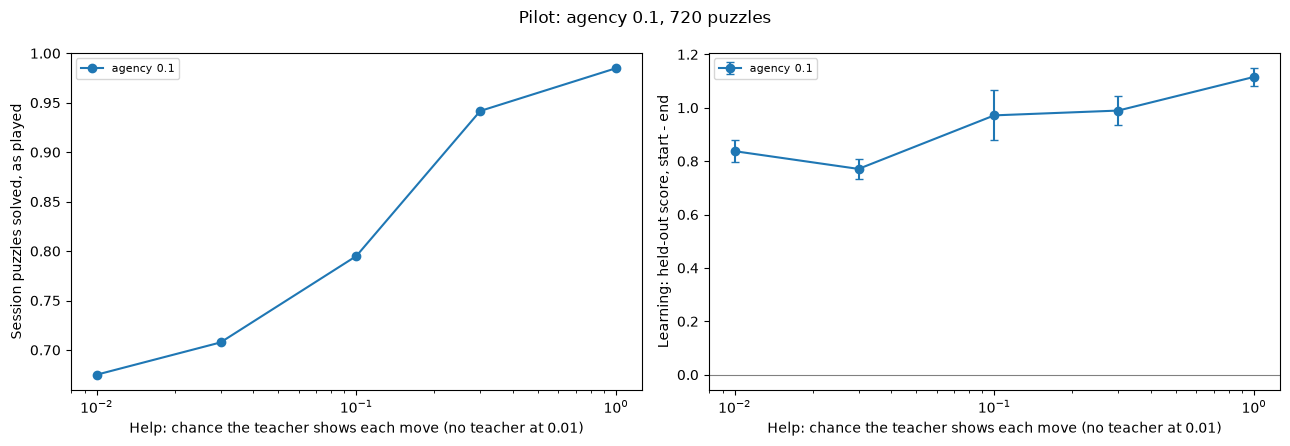

C:\Users\yijos\AppData\Local\Temp\ipykernel_30484\2183706028.py:85: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(table.round(3).fillna(""))


,agency,help,teacher,solved as played,moves shown,learning,test solve rate,score vs no teacher,better than none
0,,0.00,no teacher,0.675,0.000,+0.837 ± 0.040,0.715 ± 0.007,,
1,0.1,0.03,random 0.03,0.708,0.030,+0.771 ± 0.036,0.714 ± 0.007,+0.067 ± 0.040,2/8
2,0.1,0.10,random 0.1,0.795,0.100,+0.972 ± 0.093,0.741 ± 0.011,-0.134 ± 0.102,7/8
3,0.1,0.30,random 0.3,0.942,0.298,+0.990 ± 0.054,0.772 ± 0.006,-0.152 ± 0.060,7/8
4,0.1,1.00,random 1.0,0.985,1.000,+1.116 ± 0.033,0.778 ± 0.006,-0.278 ± 0.064,8/8


In [12]:
dilemma({0.1: PILOT_RUN}, PILOT_RUN, "Pilot: agency 0.1, 720 puzzles", "../visualization/sweep_teacher_pilot.png")

### Pilot result: no dilemma, because Adam cancels agency

At agency 0.1, learning rose with every step up in help, and full help did best:

| help | solved as played | test score at 0 → 360 → 720 puzzles | learning | vs no teacher |
|---|---|---|---|---|
| none | 0.68 | 5.56 → 5.12 → 4.72 | +0.84 ± 0.04 | |
| 0.03 | 0.71 | 5.56 → 5.02 → 4.79 | +0.77 ± 0.04 | +0.07 ± 0.04 (2/8 better) |
| 0.1 | 0.80 | 5.56 → 4.98 → 4.59 | +0.97 ± 0.09 | −0.13 ± 0.10 (7/8) |
| 0.3 | 0.94 | 5.56 → 4.89 → 4.57 | +0.99 ± 0.05 | −0.15 ± 0.06 (7/8) |
| 1.0 | 0.99 | 5.56 → 4.86 → 4.45 | +1.12 ± 0.03 | −0.28 ± 0.06 (8/8) |

Agency was only a weight on the loss, and the student trains with Adam, which divides each step by the recent size of the gradients. A weight shared by a whole batch cancels out: with every move shown, every example weighs 0.1, and the step is as large as at weight 1 (checked: 0.996 of it). So agency only set how shown moves count against the student's own within a batch, and help never cost anything except at agency exactly 0.

**Skipped steps** (`--agency-step skip`, `rl.online_update`): each update step is now taken with probability equal to its batch's mean weight, and skipped otherwise. At agency 0.1 a batch of shown moves gets a full step one time in ten, a batch of the student's own moves always does, and within a batch shown moves still count 0.1. Adam can't cancel a step that isn't taken (checked: at weight 0.1, no step 70% of the time over 3 passes; on average 0.12 of the movement at weight 1). The alternative `--agency-step scale` shrinks every step by the mean weight instead: the same learning on average, less noise.

The pilot is rerun with skipped steps, otherwise unchanged (about 1h40m).

In [13]:
PILOT_SKIP = PILOT | {"agency_step": "skip"}
PILOT_SKIP_RUN = "pilot_all_agency0.1_skip"
launch("teacher_pilot_skip", [(PILOT_SKIP_RUN, PILOT_SKIP, HELP)])

teacher_pilot_skip: all 5 teacher runs are saved, nothing to play


In [14]:
watch("teacher_pilot_skip")

teacher_pilot_skip: 100%|██████████| , finished: 5.0/5 teacher runs in 1h21m


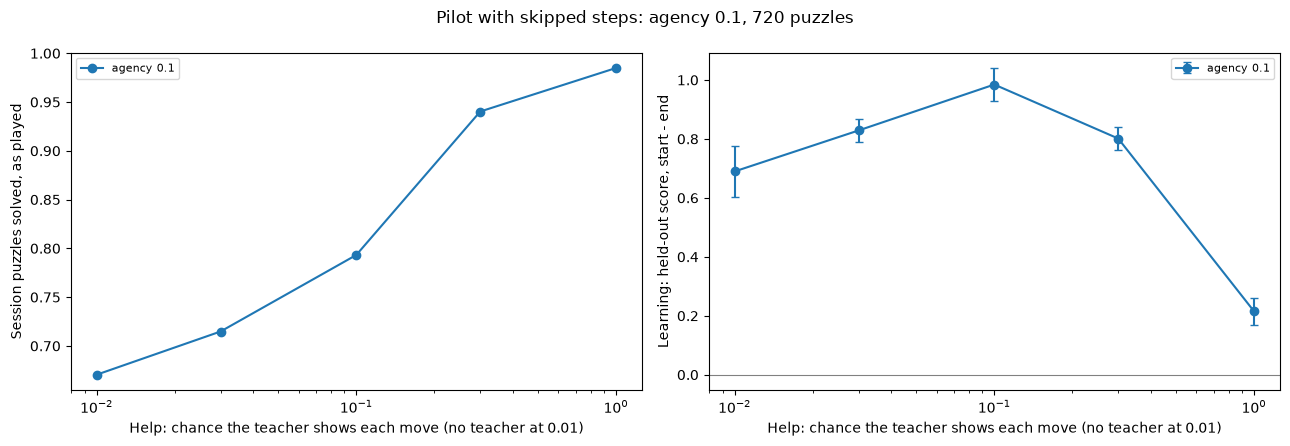

C:\Users\yijos\AppData\Local\Temp\ipykernel_30484\2183706028.py:85: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(table.round(3).fillna(""))


,agency,help,teacher,solved as played,moves shown,learning,test solve rate,score vs no teacher,better than none
0,,0.00,no teacher,0.670,0.000,+0.690 ± 0.087,0.697 ± 0.011,,
1,0.1,0.03,random 0.03,0.715,0.030,+0.829 ± 0.040,0.716 ± 0.006,-0.139 ± 0.079,6/8
2,0.1,0.10,random 0.1,0.793,0.101,+0.985 ± 0.056,0.748 ± 0.007,-0.295 ± 0.108,6/8
3,0.1,0.30,random 0.3,0.940,0.299,+0.801 ± 0.039,0.759 ± 0.006,-0.112 ± 0.086,4/8
4,0.1,1.00,random 1.0,0.985,1.000,+0.215 ± 0.046,0.700 ± 0.005,+0.475 ± 0.124,1/8


In [15]:
dilemma({0.1: PILOT_SKIP_RUN}, PILOT_SKIP_RUN, "Pilot with skipped steps: agency 0.1, 720 puzzles",
        "../visualization/sweep_teacher_pilot_skip.png")

### Pilot with skipped steps: the dilemma appears

| help | solved as played | test score at 0 → 360 → 720 puzzles | learning | vs no teacher |
|---|---|---|---|---|
| none | 0.67 | 5.56 → 5.10 → 4.87 | +0.69 ± 0.09 | |
| 0.03 | 0.72 | 5.56 → 4.99 → 4.73 | +0.83 ± 0.04 | −0.14 ± 0.08 (6/8 better) |
| 0.1 | 0.79 | 5.56 → 4.96 → 4.58 | **+0.99 ± 0.06** | −0.30 ± 0.11 (6/8) |
| 0.3 | 0.94 | 5.56 → 5.03 → 4.76 | +0.80 ± 0.04 | −0.11 ± 0.09 (4/8) |
| 1.0 | 0.99 | 5.56 → 5.46 → 5.35 | +0.22 ± 0.05 | +0.48 ± 0.12 (1/8) |

Learning peaks at help 0.1 and falls off on both sides. Full help solves nearly every session puzzle yet learns a third as much as no teacher. Help 0.1, where learning peaks, is the same in both pilots (+0.97, +0.99). Full help fell from +1.12 to +0.22, as only a tenth of its steps are now taken.

No teacher learned +0.84 in the first pilot and +0.69 here. No teacher has the same settings in both pilots; only the updates' shuffling differs, so differences of about 0.15 between runs are noise. The peak over no teacher is about 2.7 standard errors; the fall to full help is clear.

## Full sweep

Agency 0.3, 0.1 and 0, over the full 2,160-puzzle session, with skipped steps as in the second pilot. Agency 1 is left out: there help has no cost, and the first pilot already showed learning rising with help all the way to full help. That's 13 teacher runs, roughly 45 minutes each. No teacher runs once, in the agency-0.3 run, and is the baseline for all three. Set `FULL_SWEEP = True` to launch it once nothing else is running.

In [16]:
FULL_SWEEP = True
AGENCY = [0.3, 0.1, 0.0]


def sweep_run(agency):
    return f"teach_shortcut_agency{agency:g}"


SWEEP = [(sweep_run(a), SHORTCUT | {"shown_weight": a, "agency_step": "skip"},
          [t for t in HELP if t != "none" or a == AGENCY[0]]) for a in AGENCY]
if FULL_SWEEP:
    launch("teacher_sweep", SWEEP)

teacher_sweep: all 13 teacher runs are saved, nothing to play


In [17]:
watch("teacher_sweep")

teacher_sweep: 100%|██████████| , finished: 13.0/13 teacher runs in 7h56m


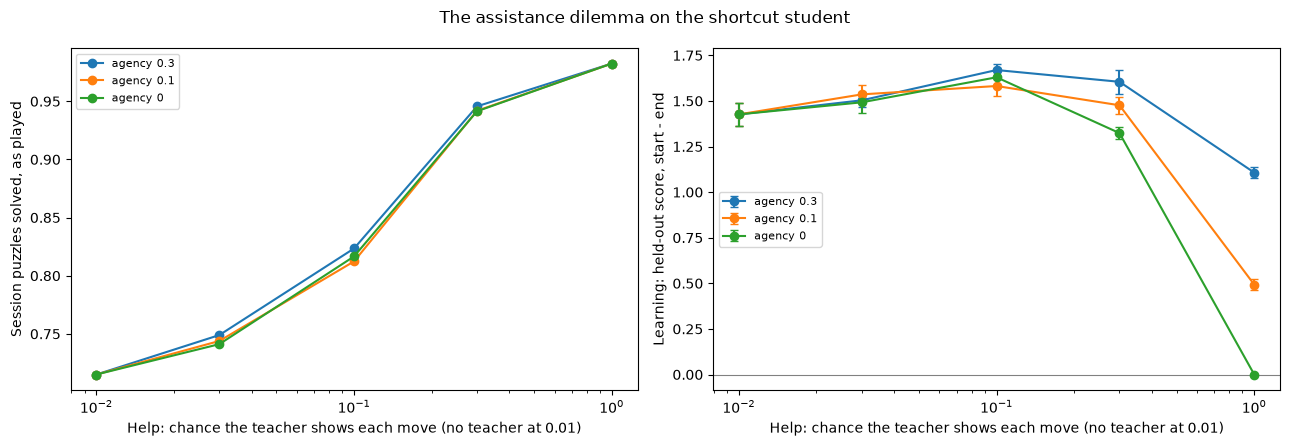

C:\Users\yijos\AppData\Local\Temp\ipykernel_30484\2183706028.py:85: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(table.round(3).fillna(""))


,agency,help,teacher,solved as played,moves shown,learning,test solve rate,score vs no teacher,better than none
0,,0.00,no teacher,0.715,0.000,+1.426 ± 0.064,0.758 ± 0.006,,
1,0.3,0.03,random 0.03,0.749,0.030,+1.503 ± 0.035,0.774 ± 0.005,-0.077 ± 0.049,5/8
2,0.3,0.10,random 0.1,0.823,0.100,+1.669 ± 0.036,0.804 ± 0.003,-0.243 ± 0.078,7/8
3,0.3,0.30,random 0.3,0.946,0.299,+1.605 ± 0.065,0.830 ± 0.007,-0.179 ± 0.078,7/8
4,0.3,1.00,random 1.0,0.982,1.000,+1.107 ± 0.031,0.783 ± 0.002,+0.319 ± 0.088,0/8
5,0.1,0.03,random 0.03,0.744,0.030,+1.536 ± 0.049,0.774 ± 0.007,-0.110 ± 0.080,6/8
6,0.1,0.10,random 0.1,0.812,0.100,+1.582 ± 0.056,0.797 ± 0.007,-0.156 ± 0.100,6/8
7,0.1,0.30,random 0.3,0.942,0.299,+1.476 ± 0.048,0.819 ± 0.005,-0.050 ± 0.086,6/8
8,0.1,1.00,random 1.0,0.982,1.000,+0.493 ± 0.029,0.725 ± 0.005,+0.933 ± 0.086,0/8
9,0.0,0.03,random 0.03,0.741,0.030,+1.492 ± 0.059,0.771 ± 0.008,-0.066 ± 0.107,5/8


In [18]:
dilemma({a: sweep_run(a) for a in AGENCY}, sweep_run(AGENCY[0]), "The assistance dilemma on the shortcut student",
        "../visualization/sweep_teacher_dilemma.png")

### Full sweep result (2026-11-05, 7h56m)

End score minus no teacher's, paired by student (below 0: the teacher helped learning; no teacher learned +1.43, 5.56 → 4.13):

| help | agency 0.3 | agency 0.1 | agency 0 |
|---|---|---|---|
| 0.03 | −0.08 ± 0.05 (5/8) | −0.11 ± 0.08 (6/8) | −0.07 ± 0.11 (5/8) |
| **0.1** | **−0.24 ± 0.08 (7/8)** | **−0.16 ± 0.10 (6/8)** | **−0.20 ± 0.09 (6/8)** |
| 0.3 | −0.18 ± 0.08 (7/8) | −0.05 ± 0.09 (6/8) | +0.10 ± 0.08 (2/8) |
| 1.0 | +0.32 ± 0.09 (0/8) | +0.93 ± 0.09 (0/8) | +1.43 ± 0.06 (0/8) |

- **The dilemma appears at every agency.** Learning peaks at help 0.1 and full help learns least, though it solves 98% of the session puzzles.
- **Agency moves the right side of the curve.** The lower the agency, the more too much help costs: full help falls from +0.32 to +1.43 behind no teacher, and help 0.3 goes from helping (agency 0.3) to hurting (agency 0). On this grid the peak stays at 0.1; a finer grid around it would be needed to see it move.
- **Light help pays even at agency 0, where shown moves teach nothing.** Help 0.1 raises session solves from 72% to 82%, and the labels come from solved attempts, so the student's own moves in puzzles it would otherwise have failed become examples. The help works by getting it unstuck, not by what it shows.
- **The gap grows with practice.** At agency 0.3 help 0.1 is −0.09 behind no teacher after 540 puzzles and −0.24 after 2,160; full help's cost is there from the first test.
- **Precision.** The peak is 2-3 standard errors from no teacher, and the agencies' peaks don't differ beyond noise. Most of that noise is the played test (about 0.15 per student); the saved networks can be re-scored with a noise-free test.

# The Bayesian teacher on the shortcut student

`teach.Bayesian` holds beliefs about the student (skill by distance to the goal, each puzzle's difficulty, how it errs, how persistent it is) and plans each puzzle to get it solved: it shows a move when its expected gain in solving beats a cost per move shown. With `bayes:b` that cost adjusts itself so that about a share `b` of the moves are shown, so `bayes:b` spends what `random:b` does; only where it spends differs.

**Baseline: the budget-matched teacher at agency 0.** Shown moves teach nothing there, so any learning a teacher adds comes from getting the student through puzzles it would fail, whose own moves then become examples - exactly where this teacher steps in. `bayes:0.03`, `0.1` and `0.3` are added to the agency-0 run (CPU training, as that run was), so each is compared with `random` at the same budget on the same 8 students, puzzles and tests; no teacher comes from the agency-0.3 run, as in the sweep. About 1-1.5 hours.

Its objective is still solving the current puzzle, which the sweep showed is not the same as learning; a learning-aware version comes next.

In [19]:
BAYES = ["bayes:0.03", "bayes:0.1", "bayes:0.3"]
BAYES_RUN = sweep_run(0.0)
launch("bayes_agency0", [(BAYES_RUN, SHORTCUT | {"shown_weight": 0.0, "agency_step": "skip"}, BAYES)])

bayes_agency0: all 3 teacher runs are saved, nothing to play


In [20]:
watch("bayes_agency0")

bayes_agency0: 100%|██████████| , finished: 3.0/3 teacher runs in 2h21m


**Results.** Each teacher's end score against no teacher's and against random help at the budget nearest its share of moves shown, student by student (below 0: its students learned more).

In [21]:
import math

def paired(e, base):
    """End score minus `base`'s, student by student: (mean, standard error), and how many did better."""
    end, b = final(e), final(base)
    d = [end[s][0] - b[s][0] for s in end if s in b]
    return te.mean_se(d), f"{sum(x < 0 for x in d)}/{len(d)}"


def teacher_table(run, specs, none_run=sweep_run(AGENCY[0])):
    """Each teacher in `specs` against no teacher and against random help at the nearest budget, paired by
    student (end score difference; below 0: the teacher's students learned more)."""
    none = entry(none_run, "none")
    randoms = {float(t.split(":")[1]): entry(run, t) for t in HELP if t != "none"}
    rows = []
    for spec in specs:
        e = entry(run, spec)
        if e is None:
            continue
        records = [x for record in e["sessions"].values() for x in record]
        shown = sum(x["taught"] for x in records) / sum(x["moves"] for x in records)
        start = measures(e["results"][0][0], e["config"])[0]
        row = {"teacher": se.teacher_name(spec), "solved as played": np.mean([x["solved"] for x in records]),
               "moves shown": shown, "learning": te.mean_se([start - v[0] for v in final(e).values()])}
        (m, s), better = paired(e, none)
        row["vs no teacher"] = f"{m:+.3f} ± {s:.3f} ({better})"
        if spec.split(":")[0] != "random":
            budget = min(randoms, key=lambda b: abs(math.log(b) - math.log(max(shown, 1e-3))))
            (m, s), better = paired(e, randoms[budget])
            row[f"vs random (nearest budget)"] = f"random {budget:g}: {m:+.3f} ± {s:.3f} ({better})"
        rows.append(row)
    table = pd.DataFrame(rows)
    table["learning"] = [f"{m:+.3f} ± {s:.3f}" for m, s in table["learning"]]
    display(table.round(3))


teacher_table(BAYES_RUN, [t for t in HELP if t != "none"] + BAYES + ["bayes-learn:0"])

,teacher,solved as played,moves shown,learning,vs no teacher,vs random (nearest budget)
0,random 0.03,0.741,0.030,+1.492 ± 0.059,-0.066 ± 0.107 (5/8),NaN
1,random 0.1,0.817,0.100,+1.630 ± 0.051,-0.203 ± 0.088 (6/8),NaN
2,random 0.3,0.941,0.299,+1.324 ± 0.033,+0.103 ± 0.079 (2/8),NaN
3,random 1.0,0.982,1.000,+0.000 ± 0.000,+1.426 ± 0.064 (0/8),NaN
4,bayes 0.03,0.863,0.030,+1.819 ± 0.045,-0.392 ± 0.087 (8/8),random 0.03: -0.326 ± 0.064 (8/8)
5,bayes 0.1,0.927,0.098,+1.473 ± 0.046,-0.047 ± 0.091 (5/8),random 0.1: +0.156 ± 0.073 (1/8)
6,bayes 0.3,0.973,0.298,+0.858 ± 0.038,+0.568 ± 0.073 (0/8),random 0.3: +0.465 ± 0.064 (0/8)
7,bayes-learn 0,0.897,0.053,+1.641 ± 0.048,-0.214 ± 0.088 (6/8),random 0.03: -0.148 ± 0.080 (5/8)


## The learning-aware teacher

`teach.LearningBayesian` (`bayes-learn:a`, a = the agency it assumes) keeps the Bayesian teacher's beliefs and planning but values a puzzle by what the student learns from it. The student learns only from the puzzles it solves, and a shown move teaches `a` of what one of its own does, so a solved puzzle is worth about 1 - (1 - a) x the share of its moves that were shown, an unsolved one nothing. In the plan, each move shown costs (1 - a) / n times the chance of then solving, n the moves a solved attempt at this puzzle is expected to take (the student's recent moves / optimal on solved puzzles, times the puzzle's optimal length); summed over the moves shown that is exactly the expected value above, under the teacher's model of the student.

There is no budget: it shows where turning a likely failure into a solve outweighs the share of the solve it takes away, and that falls as the student improves (help fades). At agency 0 it should show less than the budget-matched teacher and only where the student would otherwise fail. Added to the agency-0 run, so it is paired with the same students and with random help at its own spending.

In [22]:
launch("bayes_learn_agency0", [(BAYES_RUN, SHORTCUT | {"shown_weight": 0.0, "agency_step": "skip"}, ["bayes-learn:0"])])

bayes_learn_agency0: all 1 teacher runs are saved, nothing to play


In [23]:
watch("bayes_learn_agency0")

bayes_learn_agency0: 100%|██████████| , finished: 1.0/1 teacher runs in 55m


## Calibrating the Bayesian teacher's model of the student

The Bayesian teachers' predicted chance of solving untaught (`predicted_solve`) is too optimistic: 0.83 against 0.72
for the same students unhelped, and 0.76 against 0.46 on 24-26-move puzzles. The sessions don't keep move-by-move
paths, so `trace` - a teacher that never helps and records each puzzle's distance-to-goal path - plays the agency 0
run's sessions (unhelped, so its students are no teacher's). The model is then refitted offline by replaying those paths.

In [24]:
TRACE_RUN = sweep_run(0.0)
launch("trace_agency0", [(TRACE_RUN, SHORTCUT | {"shown_weight": 0.0, "agency_step": "skip"}, ["trace"])])

trace_agency0: all 1 teacher runs are saved, nothing to play


In [25]:
watch("trace_agency0")

trace_agency0: 100%|██████████| , finished: 1.0/1 teacher runs in 36m


### Calibration result

Replaying the traced paths through each model of the student (4 students x 2160 puzzles; predicted chance of solving
untaught at the start of each puzzle / share actually solved):

| model | Brier | 9-11 | 14-16 | 19-21 | 24-26 |
|---|---|---|---|---|---|
| solved | - | 0.95 | 0.81 | 0.62 | 0.43 |
| Bayesian (`bayes`, `bayes-learn`) | 0.200 | 0.89 | 0.82 | 0.77 | 0.73 |
| + distance from the start | 0.178 | 0.94 | 0.80 | 0.67 | 0.58 |
| + both up to 16, longer memory (`bayes2`, `bayes-learn2`) | 0.173 | 0.95 | 0.81 | 0.65 | 0.53 |
| wider puzzle spread (tau 1-2) | 0.175-0.189 | flattens every length toward the middle | | | |

Why: a move's chance of being optimal is high at both ends of a puzzle - the first move from the start (the
farthest board, where no move makes things worse) is optimal 85% of the time - and about 0.37 in the middle. With
only distance to the goal, a long puzzle's middle borrowed the easy starts of short puzzles at the same distance.
What is left on long puzzles is the puzzle itself: a third of the outcome variance is which puzzle it is, and 117 of
540 24-26-move puzzles were solved by none of the 8 students - a bottleneck no per-move shift represents. Failures
there are as much wandering to the 250-move cap (24%) as giving up (32%).

## Helping only when stuck

The wall teacher (`wall`: show one move when the student is back at its closest approach after a long stall) helped
too little: only 60% of the puzzles it stepped in on were solved. `stuck-bayes` keeps its "when" - nothing until the
student has made a puzzle-length of its own moves without getting closer than ever - and takes "how much" from the
calibrated Bayesian model: from then on, wherever the student is, it shows the move whenever the model gives the
student under `theta` chance of solving alone from there.

Mini live test (2 students x 80 puzzles, agency 0; own-solve credit = solved x share of moves the student's own):

| teacher | shown | solved | solved, 19+ | own-solve credit |
|---|---|---|---|---|
| none | 0% | 0.65 | 0.46 | 0.650 |
| random 6% | 5.8% | 0.69 | 0.50 | 0.651 |
| bayes2 4.5% | 4.2% | 0.81 | 0.74 | 0.781 |
| stuck-bayes 0.3 | 4.3% | 0.83 | 0.74 | 0.812 |
| bayes2 6.5% | 6.3% | 0.88 | 0.81 | 0.827 |
| stuck-bayes 0.5 | 6.3% | 0.88 | 0.81 | 0.835 |

The full run: one budget each, about 4.5%. stuck-bayes has no budget, so its spend over the whole session may drift
from the mini test's; the comparison with random is then read off the random 3% / 10% runs as well.

In [26]:
STUCK = ["stuck-bayes:0.3", "bayes2:0.045", "random:0.045"]
launch("stuck_agency0", [(BAYES_RUN, SHORTCUT | {"shown_weight": 0.0, "agency_step": "skip"}, STUCK)])

stuck_agency0: all 3 teacher runs are saved, nothing to play


In [27]:
watch("stuck_agency0")

stuck_agency0: 100%|██████████| , finished: 3.0/3 teacher runs in 2h10m


In [28]:
teacher_table(BAYES_RUN, STUCK)

,teacher,solved as played,moves shown,learning,vs no teacher,vs random (nearest budget)
0,stuck-bayes 0.3,0.851,0.045,+1.768 ± 0.076,-0.341 ± 0.110 (6/8),random 0.03: -0.275 ± 0.085 (7/8)
1,bayes2 0.045,0.887,0.044,+1.679 ± 0.039,-0.253 ± 0.083 (6/8),random 0.03: -0.187 ± 0.071 (7/8)
2,random 0.045,0.761,0.045,+1.548 ± 0.037,-0.121 ± 0.067 (5/8),NaN


### Result: stuck-bayes against the Bayesian teachers (agency 0, 8 students)

| teacher | shown | solved | learning | vs random 4.5% | helped puzzles | shown per helped | helped solved | own moves on helped puzzles |
|---|---|---|---|---|---|---|---|---|
| random 4.5% | 4.5% | 0.76 | +1.55 | - | 78% | 3.7 | 0.72 | 73 |
| bayes 3% (original model) | 3.0% | 0.86 | +1.82 | | 19% | 9.5 | 0.95 | 119 |
| bayes2 4.5% (calibrated) | 4.4% | 0.89 | +1.68 | -0.13 ± 0.07 | 27% | 9.1 | 0.94 | 94 |
| stuck-bayes 0.3 | 4.5% | 0.85 | +1.77 | -0.22 ± 0.10 | 22% | 12.1 | 0.74 | 121 |

Paired by student (end score; below 0 = the first learned more): stuck-bayes - bayes2 -0.088 ± 0.064 (5/8);
stuck-bayes - bayes 3% +0.051 ± 0.063; bayes2 - bayes 3% +0.139 ± 0.034 (1/8 better) - the calibrated model teaches
worse, despite spending more. The teachers that learn most let the student play longest on the puzzles they end up
helping on (~120 own moves against bayes2's 94): the original model, overrating long puzzles, stepped in late by
accident. stuck-bayes' spend wasn't set, yet held at 4.5%, falling over the session (4.8% -> 4.0%).
Own-solve credit (the mini tests' proxy) ranks bayes2 first, so it doesn't predict learning.

## When to help: patience x agency

Does it matter *when* help comes, at a fixed amount? `stuck-bayes` waits until the student has made `patience` x the
puzzle's length of its own moves without getting closer than ever, then shows moves while the model gives it under
`theta` chance of solving alone. Each patience gets the theta that shows about 4.5% of moves in a mini test
(2 students x 80 puzzles, agency 0):

| patience | theta | shown (mini) | helped puzzles | shown per helped | helped solved |
|---|---|---|---|---|---|
| 0.5 | 0.12 | 4.4% | 26% | 14.1 | 68% |
| 1 (done) | 0.3 | 4.3% | 29% | 11.7 | 77% |
| 2 | 0.55 | ~4.5% (0.5: 4.0%, 0.7: 5.4%) | ~30% | ~10 | ~85% |
| 4 | 1.0 | 4.4% | 22% | 15.3 | 94% |

At patience 4, theta 1 means: once stalled for 4 puzzle-lengths, show every remaining move.

Agency 0 gets all four patiences; agency 0.3 gets patience 0.5, 1 and 4, agency 0.1 patience 1 and 4, each with
random 4.5% (paired control in the same run). No teacher (agency-0.3 run) is the shared baseline. 11 teacher runs
(2026-11-06/07, 8h15m; agency 0.1 patience 0.5 was dropped to fit the time).


In [29]:
WHEN_P = {0.5: "stuck-bayes:0.12,patience=0.5", 1: "stuck-bayes:0.3", 2: "stuck-bayes:0.55,patience=2",
          4: "stuck-bayes:1,patience=4"}
WHEN = [(sweep_run(0.0), SHORTCUT | {"shown_weight": 0.0, "agency_step": "skip"}, [WHEN_P[0.5], WHEN_P[2], WHEN_P[4]])]
for a, ps in ((0.3, (1, 0.5, 4)), (0.1, (1, 4))):  # agency 0.1 patience 0.5 dropped to fit 8 hours
    WHEN.append((sweep_run(a), SHORTCUT | {"shown_weight": a, "agency_step": "skip"},
                 ["random:0.045"] + [WHEN_P[p] for p in ps]))
launch("when_to_help", WHEN)


when_to_help: all 10 teacher runs are saved, nothing to play


In [30]:
watch("when_to_help")

when_to_help:  91%|█████████ | , stopped: 10.0/11 teacher runs in 45h47m


In [31]:
def stuck_grid(cells, random_spec="random:0.045"):
    """One row per (agency, teacher): spend, solves, learning, its end score against no teacher's and against
    `random_spec` in the same run, paired by student (below 0: its students learned more), how many puzzles it
    helped on and how early in them, and its spend in the first and last quarter of the session."""
    none = entry(sweep_run(AGENCY[0]), "none")
    rows = []
    for agency, run, spec in cells:
        e = entry(run, spec)
        if e is None:
            continue
        records = [x for record in e["sessions"].values() for x in record]
        helped = [x for x in records if x["taught"] > 0]
        quarter = len(next(iter(e["sessions"].values()))) // 4
        spend = [sum(x["taught"] for r in e["sessions"].values() for x in r[q * quarter:(q + 1) * quarter]) /
                 sum(x["moves"] for r in e["sessions"].values() for x in r[q * quarter:(q + 1) * quarter]) for q in (0, 3)]
        start = measures(e["results"][0][0], e["config"])[0]
        row = {"agency": agency, "teacher": se.teacher_name(spec),
               "shown": sum(x["taught"] for x in records) / sum(x["moves"] for x in records),
               "shown, 1st / last quarter": f"{spend[0]:.3f} / {spend[1]:.3f}",
               "solved as played": np.mean([x["solved"] for x in records]),
               "helped puzzles": len(helped) / len(records),
               "own moves on helped": np.mean([x["moves"] - x["taught"] for x in helped]) if helped else np.nan,
               "learning": te.mean_se([start - v[0] for v in final(e).values()])}
        (m, s), better = paired(e, none)
        row["vs no teacher"] = f"{m:+.3f} ± {s:.3f} ({better})"
        rnd = entry(run, random_spec)
        if rnd is not None and spec != random_spec:
            (m, s), better = paired(e, rnd)
            row[f"vs {se.teacher_name(random_spec)}"] = f"{m:+.3f} ± {s:.3f} ({better})"
        rows.append(row)
    table = pd.DataFrame(rows)
    if len(table):
        table["learning"] = [f"{m:+.3f} ± {s:.3f}" for m, s in table["learning"]]
    return table.round(3)


def paired_pair(run_a, spec_a, run_b, spec_b):
    """End score of a minus b's, student by student (below 0: a's students learned more)."""
    a, b = entry(run_a, spec_a), entry(run_b, spec_b)
    if a is None or b is None:
        return None
    (m, s), better = paired(a, b)
    return f"{m:+.3f} ± {s:.3f} ({better})"


WHEN_CELLS = [(a, sweep_run(a), spec) for a in (0.0, 0.3, 0.1)
              for spec in ["random:0.045"] + [WHEN_P[p] for p in (0.5, 1, 2, 4) if a == 0.0 or p in (1, 4) or (a, p) == (0.3, 0.5)]]
display(stuck_grid(WHEN_CELLS))


,agency,teacher,shown,"shown, 1st / last quarter",solved as played,helped puzzles,own moves on helped,learning,vs no teacher,vs random 0.045
0,0.0,random 0.045,0.045,0.045 / 0.045,0.761,0.781,72.490,+1.548 ± 0.037,-0.121 ± 0.067 (5/8),NaN
1,0.0,stuck-bayes 0.12 p0.5,0.036,0.039 / 0.033,0.823,0.183,143.559,+1.816 ± 0.046,-0.390 ± 0.077 (8/8),-0.268 ± 0.073 (8/8)
2,0.0,stuck-bayes 0.3,0.045,0.048 / 0.040,0.851,0.216,120.876,+1.768 ± 0.076,-0.341 ± 0.110 (6/8),-0.220 ± 0.103 (5/8)
3,0.0,stuck-bayes 0.55 p2,0.043,0.046 / 0.038,0.865,0.225,115.359,+1.771 ± 0.033,-0.345 ± 0.087 (8/8),-0.223 ± 0.039 (8/8)
4,0.0,stuck-bayes 1 p4,0.041,0.043 / 0.040,0.857,0.171,124.696,+1.540 ± 0.056,-0.114 ± 0.106 (5/8),+0.008 ± 0.057 (4/8)
5,0.3,random 0.045,0.045,0.046 / 0.045,0.768,0.780,72.172,+1.648 ± 0.060,-0.222 ± 0.107 (5/8),NaN
6,0.3,stuck-bayes 0.12 p0.5,0.034,0.037 / 0.030,0.826,0.173,146.555,+1.867 ± 0.068,-0.440 ± 0.088 (8/8),-0.218 ± 0.096 (7/8)
7,0.3,stuck-bayes 0.3,0.041,0.046 / 0.036,0.854,0.206,121.115,+1.919 ± 0.032,-0.493 ± 0.077 (8/8),-0.271 ± 0.049 (8/8)
8,0.3,stuck-bayes 1 p4,0.040,0.043 / 0.038,0.858,0.166,124.459,+1.778 ± 0.053,-0.352 ± 0.051 (8/8),-0.130 ± 0.093 (5/8)
9,0.1,random 0.045,0.045,0.045 / 0.046,0.757,0.778,73.374,+1.605 ± 0.055,-0.179 ± 0.092 (6/8),NaN


### Result: when to help (2026-11-07)

Learning (test score gain over the session; no teacher +1.43) and end score against random 4.5% in the same run,
paired by student (below 0: more learning):

| teacher | shown | agency 0 | agency 0.1 | agency 0.3 |
|---|---|---|---|---|
| random 4.5% | 4.5% | +1.55 | +1.61 | +1.65 |
| stuck-bayes p0.5 (θ 0.12) | 3.5% | +1.82 (−0.27 ± 0.07, 8/8) | - | +1.87 (−0.22 ± 0.10, 7/8) |
| stuck-bayes p1 (θ 0.3) | 4.3% | +1.77 (−0.22 ± 0.10, 5/8) | +1.91 (−0.31 ± 0.09, 7/8) | +1.92 (−0.27 ± 0.05, 8/8) |
| stuck-bayes p2 (θ 0.55) | 4.3% | +1.77 (−0.22 ± 0.04, 8/8) | - | - |
| stuck-bayes p4 (θ 1: take over) | 4.1% | +1.54 (+0.01 ± 0.06, 4/8) | +1.67 (−0.06 ± 0.08, 4/8) | +1.78 (−0.13 ± 0.09, 5/8) |

- **Patience 0.5-2 make no difference** (pairwise within ±0.05, SE 0.07-0.08). They also barely change *when* help
  comes: each patience needs its own θ for the same spend, and the two offset - a short wait with a low θ steps in
  only when the student is nearly lost. The student's own moves on helped puzzles: 144, 121, 115.
- **Taking over is what fails.** Patience 4 with θ 1 shows every remaining move once the student has stalled. Its spend,
  solves (0.86) and the student's own moves on helped puzzles (125) are like the others', yet it learns 0.23 ± 0.09,
  0.25 ± 0.07 and 0.14 ± 0.08 less than patience 1 at agency 0, 0.1 and 0.3 - at agency 0 no more than random. The
  others show a move only while the student's chance is under θ, so it soon plays on and finishes the puzzle itself.
  The penalty shrinks at agency 0.3, where the moves it shows teach something.
- **Targeted, hand-back help beats more random help.** At every agency stuck-bayes p0.5-p2 learns more than random
  10% (the sweep's best budget) with under half the help: −0.14 to −0.19 at agency 0, −0.33 at 0.1, −0.20 to −0.25
  at 0.3.
- **The calibrated model can now teach as well as the original.** At agency 0 stuck-bayes p0.5 equals the original
  (miscalibrated) Bayesian at 3% (+0.00 ± 0.04) and beats bayes2 4.5% (−0.14 ± 0.04, 7/8): waiting for the student to
  be stuck stands in for the original's optimism.
- **Agency adds to it.** Patience 1 learns 0.15 ± 0.06 more at agency 0.3 than at 0; take-over gains 0.24 ± 0.09.

So for a learning-aware teacher, "when" (within 0.5-2 puzzle-lengths of stalling) matters less than "how": give the
fewest moves that restore the student's chance, then hand the puzzle back.


## Hint and hand back

Take-over (stuck-bayes 1 p4: once stalled, every remaining move) learned 0.14-0.25 less than stuck-bayes at
matched spend. Is it handing the puzzle back that matters? Two teachers that always hand back (agency 0):

- `hint:k[,patience=p]`, no model: once stuck (patience x length own moves without getting closer than ever),
  show k optimal moves in a row, then hand back; no more help until stuck that long again.
- `hint-bayes:theta[,k=..,patience=p]`: stuck-bayes's gate and help (show while the model gives under theta chance
  of solving alone), but once the chance is back (or k shown) it hands back and the gate closes - no stepping
  straight back in when the student slides, as stuck-bayes does. Against stuck-bayes 0.3, it isolates the hand-back.

Matched to take-over's spend in a mini test (2 students x 80 puzzles, agency 0, on the PC):

| teacher | shown | helped puzzles | shown per helped | hints per helped | helped solved | solved |
|---|---|---|---|---|---|---|
| stuck-bayes 0.3 (done) | 4.5% | 29% | 12.1 | - | 0.78 | 0.83 |
| take-over, stuck-bayes 1 p4 (done) | 4.4% | 21% | 14.9 | - | 0.88 | 0.84 |
| hint-bayes 0.25 | 4.3% | 29% | 11.6 | 2.5 | 0.53 | 0.73 |
| hint 2 | 4.3% | 53% | 6.1 | 3.1 | 0.62 | 0.76 |
| hint 5 p2 | 3.9% | 36% | 7.9 | 1.6 | 0.59 | 0.76 |

Handing back costs solves (0.73-0.76 against 0.84), and at agency 0 solved puzzles are all the student learns
from: the question is whether getting control back is worth more than the lost solves. Added to the agency-0 run,
so stuck-bayes, take-over and random 4.5% are paired controls.

In [32]:
HINT = ["hint-bayes:0.25", "hint:2", "hint:5,patience=2"]
launch("hint_agency0", [(sweep_run(0.0), SHORTCUT | {"shown_weight": 0.0, "agency_step": "skip"}, HINT)])

hint_agency0: all 3 teacher runs are saved, nothing to play


In [33]:
watch("hint_agency0")

hint_agency0: 100%|██████████| , finished: 3.0/3 teacher runs in 1h09m


In [34]:
TAKE_OVER, STUCK_P1 = WHEN_P[4], WHEN_P[1]
display(stuck_grid([(0.0, sweep_run(0.0), spec) for spec in ["random:0.045", STUCK_P1, TAKE_OVER] + HINT]))
run0 = sweep_run(0.0)
for spec in HINT:
    print(f"{se.teacher_name(spec):18s} vs stuck-bayes 0.3: {paired_pair(run0, spec, run0, STUCK_P1)}   "
          f"vs take-over: {paired_pair(run0, spec, run0, TAKE_OVER)}")

,agency,teacher,shown,"shown, 1st / last quarter",solved as played,helped puzzles,own moves on helped,learning,vs no teacher,vs random 0.045
0,0.0,random 0.045,0.045,0.045 / 0.045,0.761,0.781,72.490,+1.548 ± 0.037,-0.121 ± 0.067 (5/8),NaN
1,0.0,stuck-bayes 0.3,0.045,0.048 / 0.040,0.851,0.216,120.876,+1.768 ± 0.076,-0.341 ± 0.110 (6/8),-0.220 ± 0.103 (5/8)
2,0.0,stuck-bayes 1 p4,0.041,0.043 / 0.040,0.857,0.171,124.696,+1.540 ± 0.056,-0.114 ± 0.106 (5/8),+0.008 ± 0.057 (4/8)
3,0.0,hint-bayes 0.25,0.038,0.040 / 0.036,0.814,0.219,137.631,+1.698 ± 0.024,-0.271 ± 0.075 (7/8),-0.150 ± 0.057 (6/8)
4,0.0,hint 2,0.044,0.046 / 0.042,0.772,0.422,109.563,+1.615 ± 0.039,-0.189 ± 0.079 (7/8),-0.067 ± 0.050 (4/8)
5,0.0,hint 5 p2,0.039,0.041 / 0.038,0.828,0.282,118.056,+1.690 ± 0.047,-0.264 ± 0.068 (8/8),-0.143 ± 0.035 (7/8)


hint-bayes 0.25    vs stuck-bayes 0.3: +0.070 ± 0.072 (2/8)   vs take-over: -0.158 ± 0.064 (7/8)
hint 2             vs stuck-bayes 0.3: +0.153 ± 0.087 (3/8)   vs take-over: -0.075 ± 0.061 (6/8)
hint 5 p2          vs stuck-bayes 0.3: +0.077 ± 0.098 (4/8)   vs take-over: -0.150 ± 0.056 (7/8)


### Result: hint and hand back (2026-11-08, agency 0, 8 students, on the PC)

Learning (test score gain over the session; no teacher +1.43) and end score against stuck-bayes 0.3 and take-over in
the same run, paired by student (below 0: its students learned more):

| teacher | shown | solved | helped puzzles | shown per helped | helped solved | learning | vs stuck-bayes 0.3 | vs take-over |
|---|---|---|---|---|---|---|---|---|
| random 4.5% | 4.5% | 0.76 | 78% | 3.7 | 0.72 | +1.55 ± 0.04 | | |
| stuck-bayes 0.3 | 4.5% | 0.85 | 22% | 12.1 | 0.74 | +1.77 ± 0.08 | - | |
| take-over (stuck-bayes 1 p4) | 4.1% | 0.86 | 17% | 14.4 | 0.93 | +1.54 ± 0.06 | | - |
| hint-bayes 0.25 | 3.8% | 0.81 | 22% | 10.9 | 0.57 | +1.70 ± 0.02 | +0.07 ± 0.07 (2/8) | −0.16 ± 0.06 (7/8) |
| hint 5 p2 | 3.9% | 0.83 | 28% | 8.3 | 0.65 | +1.69 ± 0.05 | +0.08 ± 0.10 (4/8) | −0.15 ± 0.06 (7/8) |
| hint 2 | 4.4% | 0.77 | 42% | 6.7 | 0.56 | +1.62 ± 0.04 | +0.15 ± 0.09 (3/8) | −0.08 ± 0.06 (6/8) |

- **Handing back beats taking over.** Both 1.6-1.7-move-burst teachers (hint-bayes 0.25, hint 5 p2) learn about
  0.15 more than take-over, 7/8 students each, while showing less (3.8-3.9% against 4.1%) and solving fewer helped
  puzzles (0.57-0.65 against 0.93). Take-over solves the most and learns the least: solves alone don't predict
  learning.
- **Closing the gate after a hint doesn't help.** hint-bayes is stuck-bayes 0.3 without stepping back in when the
  student slides; it learns a little less (+0.07 ± 0.07), at slightly lower spend. Stuck-bayes's re-entry costs
  nothing and saves solves (helped puzzles solved 0.74 against 0.57).
- **The model buys little over fixed bursts.** hint 5 p2, with no model of the student, ties hint-bayes (+1.69 vs
  +1.70). Tiny hints spread thin (hint 2: 42% of puzzles helped, 2 moves at a time) are the weakest of the three and
  not clearly better than take-over or random.

So the form that teaches best is still stuck-bayes's: wait until stuck, show only as much as restores the
student's chance, hand back, and step back in if it slides. The spends differ by up to 0.7 points; none of the
differences against stuck-bayes is significant at 8 students.

## Every teacher so far (agency 0)

All the teachers played at agency 0 (shown moves aren't learned from, update steps skipped) - where help costs the
student the most - in one run, so every student is the same across teachers. Left: learning, the test score gain over
the session (± se over 8 students), with the share of moves each showed; the dashed line is no teacher (+1.43, from the
agency-0.3 run: with no help, agency doesn't matter). Right: learning against how many session puzzles were solved as
played. Families: random (fixed rate); Bayesian (help when the model says showing is worth its cost, at a budget);
calibrated Bayesian (bayes2); stuck-bayes (wait until stuck, then show while the solve-alone chance is under theta);
take-over (stuck-bayes 1 p4: once stalled, every move); hint and hand back. Saved to
`../visualization/teacher_comparison_agency0.png`.

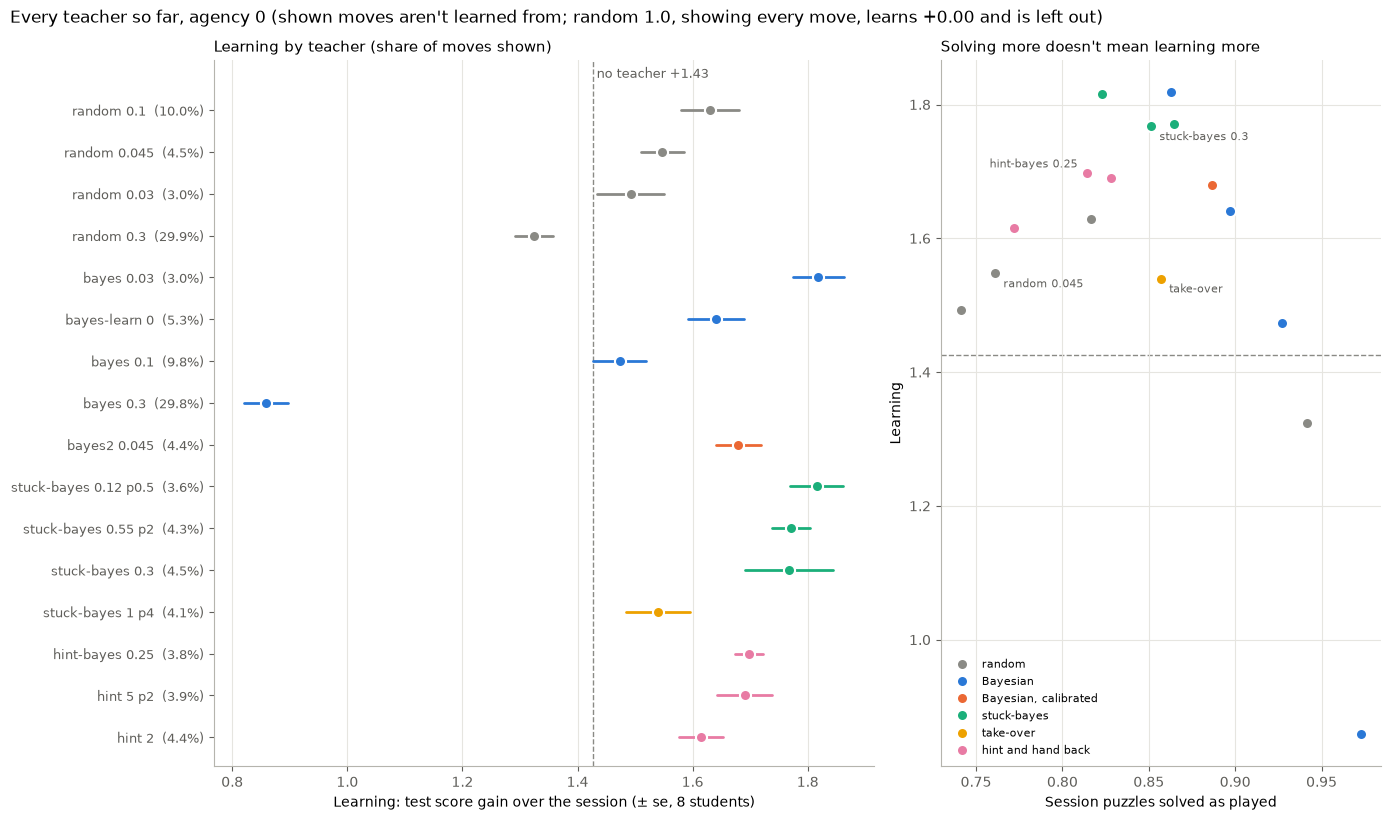

,teacher,family,learning,se,shown,solved as played
0,random 0.1,random,1.630,0.051,0.100,0.817
1,random 0.045,random,1.548,0.037,0.045,0.761
2,random 0.03,random,1.492,0.059,0.030,0.741
3,random 0.3,random,1.324,0.033,0.299,0.941
4,bayes 0.03,Bayesian,1.819,0.045,0.030,0.863
5,bayes-learn 0,Bayesian,1.641,0.048,0.053,0.897
6,bayes 0.1,Bayesian,1.473,0.046,0.098,0.927
7,bayes 0.3,Bayesian,0.858,0.038,0.298,0.973
8,bayes2 0.045,"Bayesian, calibrated",1.679,0.039,0.044,0.887
9,stuck-bayes 0.12 p0.5,stuck-bayes,1.816,0.046,0.036,0.823


In [35]:
FAMILIES = {  # family: (color - the categorical order, never cycled; neutral for the baseline)
    "random": "#8a8a85", "Bayesian": "#2a78d6", "Bayesian, calibrated": "#eb6834", "stuck-bayes": "#1baf7a",
    "take-over": "#eda100", "hint and hand back": "#e87ba4"}


def family(spec):
    kind = spec.split(":")[0]
    if kind == "random":
        return "random"
    if spec == WHEN_P[4]:
        return "take-over"
    return {"bayes": "Bayesian", "bayes-learn": "Bayesian", "bayes2": "Bayesian, calibrated",
            "stuck-bayes": "stuck-bayes", "hint": "hint and hand back",
            "hint-bayes": "hint and hand back"}[kind]


def teacher_comparison(run, specs, title, figure=None):
    """Every teacher in `run`: learning (test score gain over the session, mean ± se over students) with the share
    of moves it showed, and learning against how many session puzzles were solved as played. No teacher (from the
    agency-0.3 run) is the reference line. Saves the figure to `figure` if given; returns the table."""
    rows = []
    for spec in specs:
        e = entry(run, spec)
        if e is None:
            continue
        records = [x for record in e["sessions"].values() for x in record]
        start = measures(e["results"][0][0], e["config"])[0]
        m, s = te.mean_se([start - v[0] for v in final(e).values()])
        rows.append({"teacher": se.teacher_name(spec), "family": family(spec), "learning": m, "se": s,
                     "shown": sum(x["taught"] for x in records) / sum(x["moves"] for x in records),
                     "solved as played": np.mean([x["solved"] for x in records])})
    none = entry(sweep_run(AGENCY[0]), "none")
    base = te.mean_se([measures(none["results"][0][0], none["config"])[0] - v[0] for v in final(none).values()])[0]
    table = pd.DataFrame(rows)
    order = list(FAMILIES)
    table = table.sort_values(["family", "learning"], key=lambda c: c.map(order.index) if c.name == "family" else -c)
    table = table.reset_index(drop=True)

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 0.42 * len(table) + 1.6), width_ratios=[3, 2])
    y = np.arange(len(table))[::-1]
    for (_, r), yy in zip(table.iterrows(), y):
        c = FAMILIES[r["family"]]
        ax.plot([r["learning"] - r["se"], r["learning"] + r["se"]], [yy, yy], color=c, lw=2, solid_capstyle="round")
        ax.plot(r["learning"], yy, "o", ms=8, color=c, mec="white", mew=1.5)
    ax.axvline(base, color="#8a8a85", lw=1, ls="--", zorder=0)
    ax.text(base, y[0] + 0.7, f" no teacher {base:+.2f}", color="#5f5e5a", fontsize=9, va="bottom")
    ax.set_yticks(y, [f"{t}  ({s:.1%})" for t, s in zip(table["teacher"], table["shown"])], fontsize=9)
    ax.set_ylim(-0.7, len(table) + 0.2)
    ax.set_xlabel("Learning: test score gain over the session (± se, 8 students)")
    ax.set_title("Learning by teacher (share of moves shown)", fontsize=11, loc="left")

    for fam, c in FAMILIES.items():
        part = table[table["family"] == fam]
        ax2.plot(part["solved as played"], part["learning"], "o", ms=8, color=c, mec="white", mew=1.5, label=fam)
    for name, label, offset, ha in (("stuck-bayes 0.3", "stuck-bayes 0.3", (6, -10), "left"),
                                    ("stuck-bayes 1 p4", "take-over", (6, -10), "left"),
                                    ("random 0.045", "random 0.045", (6, -10), "left"),
                                    ("hint-bayes 0.25", "hint-bayes 0.25", (-7, 4), "right")):
        r = table[table["teacher"] == name]
        if len(r):
            ax2.annotate(label, (r["solved as played"].iloc[0], r["learning"].iloc[0]), xytext=offset, ha=ha,
                         textcoords="offset points", fontsize=8, color="#5f5e5a")
    ax2.axhline(base, color="#8a8a85", lw=1, ls="--", zorder=0)
    ax2.set_xlabel("Session puzzles solved as played")
    ax2.set_ylabel("Learning")
    ax2.set_title("Solving more doesn't mean learning more", fontsize=11, loc="left")
    ax2.legend(fontsize=8, frameon=False, loc="lower left")
    for a in (ax, ax2):
        a.grid(axis="x" if a is ax else "both", color="#e6e5e0", lw=0.8)
        a.set_axisbelow(True)
        for side in ("top", "right"):
            a.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            a.spines[side].set_color("#b5b4ad")
        a.tick_params(colors="#5f5e5a")
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    plt.tight_layout()
    if figure:
        os.makedirs(os.path.dirname(figure), exist_ok=True)
        plt.savefig(figure, dpi=150)
    plt.show()
    return table.round(3)


AGENCY0_TEACHERS = [t for t in se.load_session(sweep_run(0.0), OUT)["config"]["teachers"]
                    if t not in ("trace", "random:1.0")]
display(teacher_comparison(sweep_run(0.0), AGENCY0_TEACHERS, "Every teacher so far, agency 0 (shown moves aren't "
                           "learned from; random 1.0, showing every move, learns +0.00 and is left out)",
                           "../visualization/teacher_comparison_agency0.png"))